# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** M. Waliyul Ahdy
- **Email:** [Input Email]
- **ID Dicoding:** [Input Username]

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

Dataset yang digunakan adalah *Bike Sharing Dataset* (data penyewaan sepeda Capital Bikeshare, Washington D.C.) periode **1 Januari 2011 - 31 Desember 2012**, terdiri dari data harian (`day.csv`) dan per jam (`hour.csv`).

- **Pertanyaan 1:** Bagaimana pola rata-rata jumlah penyewaan sepeda per jam pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011-2012, dan pada jam berapa terjadi puncak penyewaan di masing-masing tipe hari, sehingga operator dapat menentukan jam prioritas penempatan dan perawatan armada?
- **Pertanyaan 2:** Seberapa besar selisih rata-rata penyewaan harian antar musim dan antar kondisi cuaca sepanjang 2011-2012, serta musim dan kondisi cuaca apa yang menghasilkan penyewaan terendah, sehingga operator dapat merencanakan kapasitas armada dan promosi musiman?

## Import Semua Packages/Library yang Digunakan

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

#### Load day.csv dan hour.csv

In [ ]:
day_df = pd.read_csv("/content/day.csv")
hour_df = pd.read_csv("/content/hour.csv")

print("day.csv :", day_df.shape)
print("hour.csv:", hour_df.shape)
day_df.head()

day.csv : (731, 16)
hour.csv: (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [ ]:
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- `day.csv` berisi 731 baris (1 baris per hari) dan `hour.csv` berisi 17.379 baris (1 baris per jam), dengan atribut yang sama ditambah kolom `hr` pada data per jam.
- Pertanyaan 1 menggunakan data per jam, sedangkan Pertanyaan 2 menggunakan data harian.

### Assessing Data

#### Identifying missing value, duplicate data, dan invalid data type

In [ ]:
for name, df in {"day": day_df, "hour": hour_df}.items():
    print(f"== {name}")
    print("Missing value :", df.isna().sum().sum())
    print("Duplikat      :", df.duplicated().sum())
print("\nTipe data day_df:")
print(day_df.dtypes)

== day
Missing value : 0
Duplikat      : 0
== hour
Missing value : 0
Duplikat      : 0

Tipe data day_df:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object


#### Identifying inconsistent, inaccurate, dan invalid value

In [ ]:
# 1) kolom kategorikal masih berupa kode angka
print(day_df[["season", "yr", "mnth", "weekday", "weathersit"]].drop_duplicates().head(3))
print("\nweathersit day :", day_df["weathersit"].value_counts().to_dict())
print("weathersit hour:", hour_df["weathersit"].value_counts().to_dict())

# 2) nilai suhu, kelembapan, dan kecepatan angin masih ternormalisasi (0-1)
print("\n", day_df[["temp", "atemp", "hum", "windspeed"]].describe().round(3))

# 3) kelengkapan data per jam (seharusnya 731 hari x 24 jam)
print("\nJam yang tidak tercatat di hour.csv:", 731 * 24 - len(hour_df))

# 4) konsistensi casual + registered = cnt
print("Selisih casual + registered - cnt:", (day_df["casual"] + day_df["registered"] - day_df["cnt"]).abs().sum())

# 5) invalid value: kelembapan (hum) bernilai 0
print("hum == 0 (day) :", day_df.loc[day_df["hum"] == 0, "dteday"].tolist())
print("hum == 0 (hour):", (hour_df["hum"] == 0).sum(), "baris")

# 6) outlier (metode IQR)
for col in ["casual", "windspeed"]:
    q1, q3 = day_df[col].quantile([0.25, 0.75])
    n_out = ((day_df[col] > q3 + 1.5 * (q3 - q1)) | (day_df[col] < q1 - 1.5 * (q3 - q1))).sum()
    print(f"Outlier {col}: {n_out} hari")

   season  yr  mnth  weekday  weathersit
0       1   0     1        6           2
1       1   0     1        0           2
2       1   0     1        1           1

weathersit day : {1: 463, 2: 247, 3: 21}
weathersit hour: {1: 11413, 2: 4544, 3: 1419, 4: 3}

           temp    atemp      hum  windspeed
count  731.000  731.000  731.000    731.000
mean     0.495    0.474    0.628      0.190
std      0.183    0.163    0.142      0.077
min      0.059    0.079    0.000      0.022
25%      0.337    0.338    0.520      0.135
50%      0.498    0.487    0.627      0.181
75%      0.655    0.609    0.730      0.233
max      0.862    0.841    0.972      0.507

Jam yang tidak tercatat di hour.csv: 165
Selisih casual + registered - cnt: 0
hum == 0 (day) : ['2011-03-10']
hum == 0 (hour): 22 baris
Outlier casual: 44 hari
Outlier windspeed: 13 hari


**Steps to Take:**
- Tidak ditemukan missing value maupun data duplikat pada kedua tabel.
- Kolom `dteday` bertipe string (object) sehingga harus diubah ke `datetime`.
- Kode kategorikal (`season`, `yr`, `mnth`, `weekday`, `weathersit`, `workingday`) akan dipetakan menjadi label yang mudah dibaca, sesuai keterangan pada Readme dataset.
- Nilai `temp`, `atemp`, `hum`, dan `windspeed` akan dikembalikan ke skala aslinya (suhu dalam °C, kelembapan dalam %, kecepatan angin dalam km/jam) berdasarkan faktor normalisasi pada Readme.
- Sebanyak 165 jam tidak tercatat pada `hour.csv` (kemungkinan tidak ada transaksi/data hilang). Data tidak diimputasi karena rata-rata per jam tetap dapat dihitung dari data yang ada.
- Kelembapan (`hum`) bernilai 0 pada 2011-03-10 tidak valid (kelembapan 0% tidak mungkin), sehingga diganti dengan median `hum` pada bulan dan tahun yang sama.
- Outlier pada `casual` dan `windspeed` dipertahankan karena merupakan variasi alami (mis. lonjakan pengguna kasual pada hari libur), bukan kesalahan input.

**Insight:**
- Tidak ada missing value maupun duplikat; `casual + registered = cnt` konsisten pada seluruh baris.
- Masalah yang ditemukan: tipe data `dteday` tidak sesuai, kode kategorikal dan nilai ternormalisasi (inconsistent/inaccurate), 165 jam tidak tercatat pada data per jam, `hum` = 0 (invalid), serta outlier pada `casual` dan `windspeed` yang dipertahankan.

### Cleaning Data

#### Fixing invalid data type, inconsistent value, dan inaccurate value

In [ ]:
season_map = {1: "Spring", 2: "Summer", 3: "Fall", 4: "Winter"}
weather_map = {1: "Clear", 2: "Mist/Cloudy", 3: "Light Snow/Rain", 4: "Heavy Rain/Snow"}
weekday_map = {0: "Minggu", 1: "Senin", 2: "Selasa", 3: "Rabu", 4: "Kamis", 5: "Jumat", 6: "Sabtu"}

def clean(df):
    df = df.copy()
    df["dteday"] = pd.to_datetime(df["dteday"])
    # invalid value: hum = 0 -> median hum pada bulan & tahun yang sama
    med = df[df["hum"] > 0].groupby(["yr", "mnth"])["hum"].median()
    nol = df["hum"] == 0
    df.loc[nol, "hum"] = [med[(y, m)] for y, m in zip(df.loc[nol, "yr"], df.loc[nol, "mnth"])]
    df["season"] = df["season"].map(season_map)
    df["yr"] = df["yr"].map({0: 2011, 1: 2012})
    df["weathersit"] = df["weathersit"].map(weather_map)
    df["weekday"] = df["weekday"].map(weekday_map)
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")
    df["temp"] = df["temp"] * 41          # °C
    df["atemp"] = df["atemp"] * 50        # °C
    df["hum"] = df["hum"] * 100           # %
    df["windspeed"] = df["windspeed"] * 67  # km/jam
    return df

day_df = clean(day_df)
hour_df = clean(hour_df)

print("Missing value setelah cleaning:", day_df.isna().sum().sum(), hour_df.isna().sum().sum())
print(day_df["dteday"].dtype)
day_df.head()

Missing value setelah cleaning: 0 0
datetime64[ns]


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,day_type
0,1,2011-01-01,Spring,2011,1,0,Sabtu,0,Mist/Cloudy,14.110847,18.18125,80.5833,10.749882,331,654,985,Akhir Pekan/Libur
1,2,2011-01-02,Spring,2011,1,0,Minggu,0,Mist/Cloudy,14.902598,17.68695,69.6087,16.652113,131,670,801,Akhir Pekan/Libur
2,3,2011-01-03,Spring,2011,1,0,Senin,1,Clear,8.050924,9.47025,43.7273,16.636703,120,1229,1349,Hari Kerja
3,4,2011-01-04,Spring,2011,1,0,Selasa,1,Clear,8.200000,10.60610,59.0435,10.739832,108,1454,1562,Hari Kerja
4,5,2011-01-05,Spring,2011,1,0,Rabu,1,Clear,9.305237,11.46350,43.6957,12.522300,82,1518,1600,Hari Kerja


In [ ]:
import os
os.makedirs("dashboard", exist_ok=True)

order_season = ["Spring", "Summer", "Fall", "Winter"]
day_df["season"] = pd.Categorical(day_df["season"], order_season, ordered=True)
hour_df["season"] = pd.Categorical(hour_df["season"], order_season, ordered=True)

day_df.to_csv("dashboard/main_data.csv", index=False)
hour_df.to_csv("dashboard/hour_data.csv", index=False)
print("Periode:", day_df["dteday"].min().date(), "s.d.", day_df["dteday"].max().date())

Periode: 2011-01-01 s.d. 2012-12-31


**Insight:**
- Seluruh kolom kategorikal telah berlabel, `dteday` bertipe `datetime`, dan nilai cuaca kembali ke satuan aslinya sehingga hasil analisis dapat diinterpretasikan langsung.
- Pada data harian, kondisi cuaca hanya terdiri dari 3 kategori (kategori *Heavy Rain/Snow* hanya muncul 3 kali pada data per jam).

## Exploratory Data Analysis (EDA)

### Explore pola penyewaan per jam

In [ ]:
hourly_df = hour_df.groupby(["day_type", "hr"])["cnt"].mean().unstack(0).round(1)
display(hourly_df.T)

for t in hourly_df.columns:
    top = hourly_df[t].nlargest(2)
    print(f"{t}: puncak pada jam {top.index[0]:02d}.00 ({top.iloc[0]:.0f} sewa/jam) dan jam {top.index[1]:02d}.00 ({top.iloc[1]:.0f} sewa/jam)")
    print(f"   terendah pada jam {hourly_df[t].idxmin():02d}.00 ({hourly_df[t].min():.0f} sewa/jam)")

hr,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
day_type,,,,,,,,,,,,,,,,,,,,,
Akhir Pekan/Libur,90.8,69.5,53.2,25.8,8.3,8.7,18.7,43.4,105.7,171.6,...,364.6,358.8,352.7,323.5,281.1,231.7,174.7,142.1,116.1,85.9
Hari Kerja,36.8,16.6,8.7,4.9,5.4,24.9,102.5,290.6,477.0,241.5,...,183.6,201.3,293.1,525.3,492.2,348.4,249.7,186.3,138.4,88.7


Akhir Pekan/Libur: puncak pada jam 13.00 (373 sewa/jam) dan jam 12.00 (366 sewa/jam)
   terendah pada jam 04.00 (8 sewa/jam)
Hari Kerja: puncak pada jam 17.00 (525 sewa/jam) dan jam 18.00 (492 sewa/jam)
   terendah pada jam 03.00 (5 sewa/jam)


### Explore pengaruh musim dan cuaca

In [ ]:
season_df = day_df.groupby("season", observed=True)["cnt"].agg(["count", "mean", "sum"]).round(0)
weather_df = day_df.groupby("weathersit")["cnt"].agg(["count", "mean", "sum"]).round(0).sort_values("mean", ascending=False)
display(season_df)
display(weather_df)

best_season, worst_season = season_df["mean"].idxmax(), season_df["mean"].idxmin()
print(f"Musim {worst_season} lebih rendah {(1 - season_df.loc[worst_season, 'mean'] / season_df.loc[best_season, 'mean']) * 100:.1f}% dibanding {best_season}")
base = weather_df["mean"].iloc[0]
for w, v in weather_df["mean"].items():
    print(f"{w:16s}: {v:,.0f} sewa/hari ({(v / base - 1) * 100:+.1f}% vs Clear)")

print("\nKorelasi dengan cnt:")
print(day_df[["cnt", "temp", "hum", "windspeed"]].corr()["cnt"].round(2))

yearly = day_df.groupby("yr")["cnt"].sum()
print(f"\nTotal 2011: {yearly[2011]:,} | 2012: {yearly[2012]:,} | pertumbuhan {(yearly[2012] / yearly[2011] - 1) * 100:.1f}%")

,count,mean,sum
season,,,
Spring,181,2604.0,471348
Summer,184,4992.0,918589
Fall,188,5644.0,1061129
Winter,178,4728.0,841613


,count,mean,sum
weathersit,,,
Clear,463,4877.0,2257952
Mist/Cloudy,247,4036.0,996858
Light Snow/Rain,21,1803.0,37869


Musim Spring lebih rendah 53.9% dibanding Fall
Clear           : 4,877 sewa/hari (+0.0% vs Clear)
Mist/Cloudy     : 4,036 sewa/hari (-17.2% vs Clear)
Light Snow/Rain : 1,803 sewa/hari (-63.0% vs Clear)

Korelasi dengan cnt:
cnt          1.00
temp         0.63
hum         -0.11
windspeed   -0.23
Name: cnt, dtype: float64

Total 2011: 1,243,103 | 2012: 2,049,576 | pertumbuhan 64.9%


**Insight:**
- Pada hari kerja terdapat dua puncak penyewaan (jam 08.00 dan 17.00) yang sesuai jam berangkat dan pulang kerja, sedangkan akhir pekan membentuk satu puncak lebar pada siang hari (jam 12.00-15.00).
- Rata-rata penyewaan tertinggi terjadi pada musim Fall dan terendah pada Spring; kondisi cuaca buruk (Light Snow/Rain) menurunkan penyewaan secara drastis.
- Suhu berkorelasi positif sedang dengan jumlah penyewaan (r = 0,63), sedangkan kelembapan hampir tidak berkorelasi.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pola penyewaan per jam pada hari kerja vs akhir pekan/libur

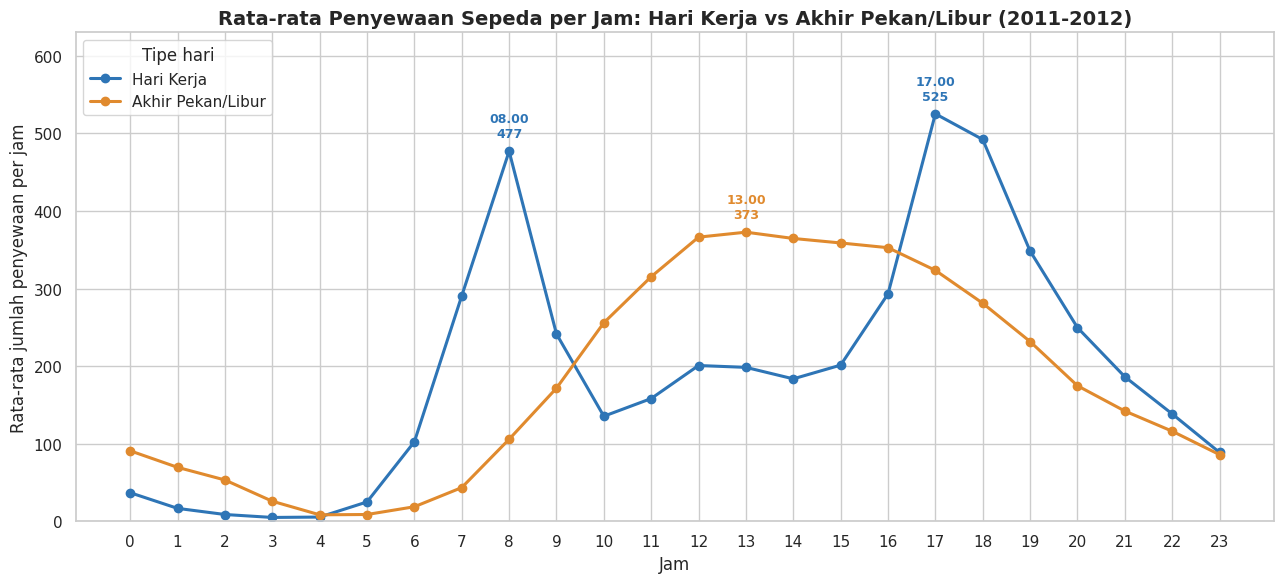

In [ ]:
fig, ax = plt.subplots(figsize=(13, 6))
styles = {"Hari Kerja": "#2E75B6", "Akhir Pekan/Libur": "#E08A2E"}
for t, color in styles.items():
    ax.plot(hourly_df.index, hourly_df[t], marker="o", linewidth=2.2, color=color, label=t)

for t, color in styles.items():
    for hr in [8, 17] if t == "Hari Kerja" else [hourly_df[t].idxmax()]:
        v = hourly_df.loc[hr, t]
        ax.annotate(f"{hr:02d}.00\n{v:.0f}", (hr, v), textcoords="offset points", xytext=(0, 10),
                    ha="center", fontsize=9, fontweight="bold", color=color)

ax.set_xticks(range(0, 24))
ax.set_xlabel("Jam")
ax.set_ylabel("Rata-rata jumlah penyewaan per jam")
ax.set_ylim(0, hourly_df.max().max() * 1.2)
ax.set_title("Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Akhir Pekan/Libur (2011-2012)", fontsize=14, fontweight="bold")
ax.legend(title="Tipe hari", loc="upper left")
plt.tight_layout()
plt.show()

### Pertanyaan 2: Pengaruh musim dan kondisi cuaca terhadap penyewaan harian

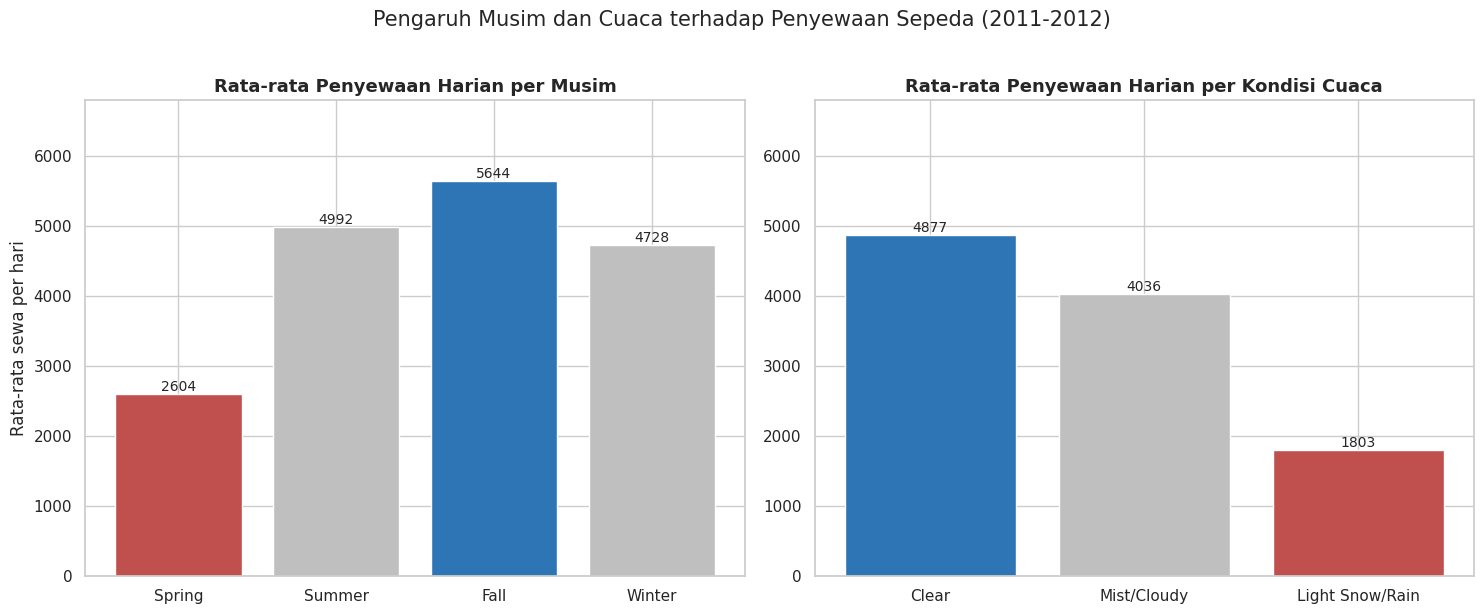

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

s = season_df["mean"]
colors_s = ["#C0504D" if v == s.min() else "#2E75B6" if v == s.max() else "#BFBFBF" for v in s]
ax[0].bar(s.index.astype(str), s.values, color=colors_s)
ax[0].bar_label(ax[0].containers[0], fmt="%.0f", fontsize=10)
ax[0].set_title("Rata-rata Penyewaan Harian per Musim", fontsize=13, fontweight="bold")
ax[0].set_ylabel("Rata-rata sewa per hari"); ax[0].set_xlabel("")

w = weather_df["mean"]
colors_w = ["#C0504D" if v == w.min() else "#2E75B6" if v == w.max() else "#BFBFBF" for v in w]
ax[1].bar(w.index, w.values, color=colors_w)
ax[1].bar_label(ax[1].containers[0], fmt="%.0f", fontsize=10)
ax[1].set_title("Rata-rata Penyewaan Harian per Kondisi Cuaca", fontsize=13, fontweight="bold")
ax[1].set_ylabel(""); ax[1].set_xlabel("")

for a in ax:
    a.set_ylim(0, 6800)
fig.suptitle("Pengaruh Musim dan Cuaca terhadap Penyewaan Sepeda (2011-2012)", fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

**Insight:**
- Hari kerja memiliki dua puncak tajam pada jam **08.00 (sekitar 477 sewa/jam)** dan **17.00 (sekitar 525 sewa/jam)**, sedangkan akhir pekan/libur memuncak pada jam **13.00 (sekitar 373 sewa/jam)**. Penyewaan pada dini hari (jam 02.00-05.00) sangat rendah di kedua tipe hari.
- Rata-rata penyewaan harian tertinggi terjadi pada musim **Fall (5.644)** dan terendah pada **Spring (2.604)**, atau 53,9% lebih rendah. Cuaca *Mist/Cloudy* menurunkan penyewaan 17,2% dibanding *Clear*, sedangkan *Light Snow/Rain* menurunkannya hingga 63,0% (1.803 vs 4.877 sewa/hari).

## Analisis Lanjutan (Opsional)

### Clustering dengan Manual Grouping dan Binning

Teknik ini mengelompokkan hari-hari ke dalam kelompok berdasarkan aturan bisnis tanpa algoritma machine learning:
- **Binning suhu** (`temp`, °C): *Dingin* (< 10), *Sejuk* (10-20), *Hangat* (20-30), *Panas* (> 30).
- **Binning tingkat permintaan** (`cnt`): *Rendah* (< 3.000 sewa/hari), *Sedang* (3.000-6.000), *Tinggi* (> 6.000).

Tujuannya untuk melihat pada rentang suhu mana permintaan optimal dan karakteristik cuaca pada tiap tingkat permintaan, serta komposisi pengguna *casual* vs *registered*.

,jumlah_hari,casual,registered,total,casual_pct
temp_group,,,,,
Dingin (<10°C),60,123.0,1555.0,1678.0,7.3
Sejuk (10-20°C),299,563.0,3129.0,3692.0,15.2
Hangat (20-30°C),300,1209.0,4453.0,5662.0,21.4
Panas (>30°C),72,1132.0,4278.0,5410.0,20.9


,jumlah_hari,suhu,kelembapan,angin
demand_level,,,,
Rendah,172,12.4,64.3,14.8
Sedang,379,21.4,63.2,12.5
Tinggi,180,25.6,60.8,11.3


,casual,registered,casual_pct
day_type,,,
Akhir Pekan/Libur,1371.1,2959.0,31.7
Hari Kerja,606.6,3978.2,13.2


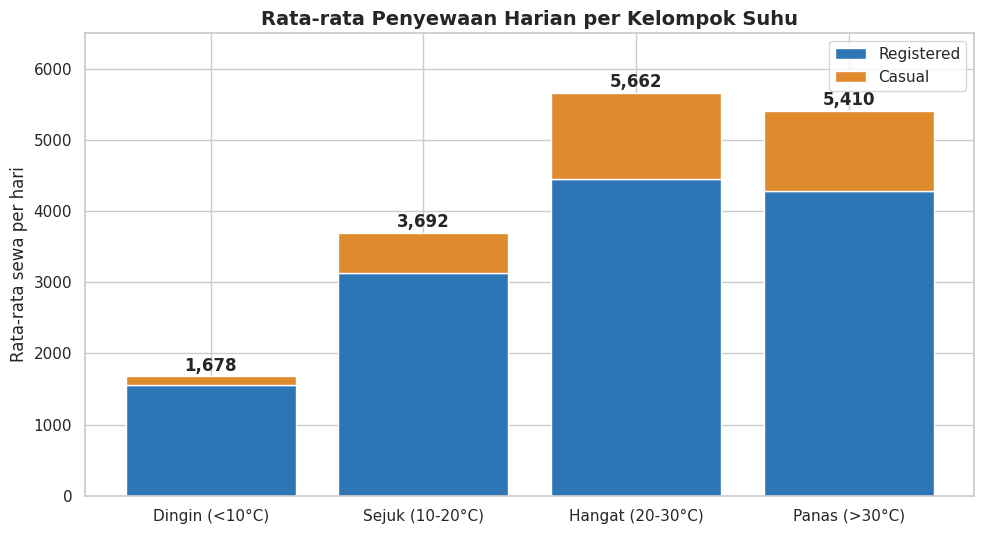

In [ ]:
day_df["temp_group"] = pd.cut(day_df["temp"], bins=[-10, 10, 20, 30, 50],
                              labels=["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"])
day_df["demand_level"] = pd.cut(day_df["cnt"], bins=[0, 3000, 6000, 10000],
                                labels=["Rendah", "Sedang", "Tinggi"])

temp_df = day_df.groupby("temp_group", observed=True).agg(
    jumlah_hari=("cnt", "size"), casual=("casual", "mean"), registered=("registered", "mean"), total=("cnt", "mean")).round(0)
temp_df["casual_pct"] = (temp_df["casual"] / temp_df["total"] * 100).round(1)
display(temp_df)

level_df = day_df.groupby("demand_level", observed=True).agg(
    jumlah_hari=("cnt", "size"), suhu=("temp", "mean"), kelembapan=("hum", "mean"), angin=("windspeed", "mean")).round(1)
display(level_df)

daytype_df = day_df.groupby("day_type")[["casual", "registered"]].mean()
daytype_df["casual_pct"] = daytype_df["casual"] / daytype_df.sum(axis=1) * 100
display(daytype_df.round(1))

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(temp_df.index.astype(str), temp_df["registered"], color="#2E75B6", label="Registered")
ax.bar(temp_df.index.astype(str), temp_df["casual"], bottom=temp_df["registered"], color="#E08A2E", label="Casual")
for i, tot in enumerate(temp_df["total"]):
    ax.text(i, tot + 80, f"{tot:,.0f}", ha="center", fontweight="bold")
ax.set_ylabel("Rata-rata sewa per hari"); ax.set_ylim(0, 6500)
ax.set_title("Rata-rata Penyewaan Harian per Kelompok Suhu", fontsize=14, fontweight="bold")
ax.legend()
plt.tight_layout(); plt.show()

**Insight:**
- Penyewaan tertinggi terjadi pada suhu **Hangat (20-30°C)** dengan rata-rata 5.662 sewa/hari, sedikit turun pada suhu **Panas (>30°C)** menjadi 5.410, dan sangat rendah pada suhu **Dingin (<10°C)** yaitu 1.678.
- Hari dengan permintaan *Tinggi* (180 hari) memiliki suhu rata-rata 25,6°C, jauh lebih hangat dibanding hari *Rendah* (172 hari) yang rata-rata 12,4°C.
- Pengguna *casual* menyumbang 31,7% penyewaan pada akhir pekan/libur, namun hanya 13,2% pada hari kerja, sehingga pengguna *registered* lebih mendominasi aktivitas komuter.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pola penyewaan sangat dipengaruhi tipe hari. Pada hari kerja terdapat dua puncak komuter pada jam **08.00 (sekitar 477 sewa/jam)** dan **17.00 (sekitar 525 sewa/jam)**, sedangkan pada akhir pekan/libur penyewaan memuncak pada jam **13.00 (sekitar 373 sewa/jam)**. Jam 02.00-05.00 adalah periode dengan permintaan terendah.
- **Conclusion pertanyaan 2:** Musim **Fall** memiliki rata-rata penyewaan harian tertinggi (5.644) dan **Spring** terendah (2.604, turun 53,9%). Cuaca *Light Snow/Rain* menurunkan penyewaan 63,0% dibanding cuaca *Clear* (1.803 vs 4.877 sewa/hari), sedangkan *Mist/Cloudy* menurunkannya 17,2%.
- **Analisis lanjutan:** Penyewaan optimal pada suhu 20-30°C dan jumlah penyewaan tahun 2012 tumbuh 64,9% dibanding 2011.

**Rekomendasi Action Item:**
- Pastikan ketersediaan sepeda dan lakukan redistribusi (*rebalancing*) antar stasiun sebelum jam 07.00 dan jam 16.00 pada hari kerja, serta tambah ketersediaan sepeda siang hari (12.00-15.00) di lokasi wisata/rekreasi pada akhir pekan.
- Jadwalkan perawatan armada pada jam 00.00-05.00 karena permintaan paling rendah.
- Berikan promosi atau diskon pada musim Spring dan saat cuaca *Mist/Cloudy* untuk menaikkan permintaan yang rendah, serta kurangi jumlah sepeda yang beroperasi saat cuaca buruk (*Light Snow/Rain*).
- Targetkan kampanye pengguna *casual* pada akhir pekan dengan penawaran keanggotaan, karena proporsi pengguna *casual* jauh lebih tinggi pada hari tersebut.